# M vs H hysteresis loops — out-of-plane and in-plane

Reads two M–H loops and plots them:
* **Sheet 1 → out-of-plane** (H ⊥ film plane)
* **Sheet 2 → in-plane** (H ∥ film plane)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## Settings

In [24]:
OOP_CSV = "979D_Fe_GroupC_OUT.csv"      # out-of-plane  (H perpendicular to film)
IP_CSV  = "979D_Fe_GroupC_IP.csv"          # in-plane      (H parallel to film)

SOURCES = {
    "Out-of-plane": OOP_CSV,
    "In-plane":     IP_CSV,
}

SAMPLE_NAME = "Fe on Si Substrated Group C"

# Subtract a linear (dia/paramagnetic) background fitted to the high-field part of the loop
SUBTRACT_BACKGROUND = False
HIGH_FIELD_FRACTION = 0.8      # use |H| > 0.8*Hmax for the background fit and for Ms

# Optional: convert moment (emu) to magnetization (emu/cm^3). Leave as None to plot in emu.
FILM_THICKNESS_NM = None       # e.g. 30
FILM_AREA_MM2     = None       # e.g. 5 * 5

SHOW_VIRGIN_CURVE = True       # plot the initial magnetization curve (first sweep 0 -> +Hmax)
SAVE_FIGURES = True
OUT_DIR = Path("figures")

## Load data

In [25]:
def load_loop(path):
    """Read a 2-column M-H CSV (Field, Moment). Returns DataFrame with columns H, M."""
    df = pd.read_csv(path, encoding="utf-8-sig", header=0)
    df = df.iloc[:, :2]
    df.columns = ["H", "M"]
    # drop units row ("G", "emu") and any blank/non-numeric rows
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
    return df

loops = {}
for label, path in SOURCES.items():
    if not Path(path).exists():
        print(f"{label:13s}: file not found -> {path}  (skipped)")
        continue
    loops[label] = load_loop(path)
    d = loops[label]
    print(f"{label:13s}: {len(d)} points, H = {d.H.min():.0f} to {d.H.max():.0f}, "
          f"M = {d.M.min():.3e} to {d.M.max():.3e} emu")

Out-of-plane : 1001 points, H = -9992 to 9982, M = -1.080e-03 to 1.100e-03 emu
In-plane     : 1451 points, H = -9976 to 9953, M = -2.610e-04 to 2.610e-04 emu


## Processing: split branches, background, units

In [26]:
def split_branches(d):
    """Split a full sweep (0 -> +Hmax -> -Hmax -> +Hmax) into virgin, descending and ascending branches."""
    H = d.H.values
    i_max, i_min = int(np.argmax(H)), int(np.argmin(H))
    if i_max < i_min:      # starts going to +H
        virgin, desc, asc = d.iloc[:i_max + 1], d.iloc[i_max:i_min + 1], d.iloc[i_min:]
    else:                  # starts going to -H
        virgin, asc, desc = d.iloc[:i_min + 1], d.iloc[i_min:i_max + 1], d.iloc[i_max:]
    return virgin.reset_index(drop=True), desc.reset_index(drop=True), asc.reset_index(drop=True)


def subtract_linear_background(d, frac):
    """Fit M = chi*H + c separately at +high and -high field, remove the average slope."""
    Hmax = d.H.abs().max()
    hi = d[d.H > frac * Hmax]
    lo = d[d.H < -frac * Hmax]
    chi = np.mean([np.polyfit(hi.H, hi.M, 1)[0], np.polyfit(lo.H, lo.M, 1)[0]])
    out = d.copy()
    out["M"] = d.M - chi * d.H
    return out, chi


def volume_cm3():
    if FILM_THICKNESS_NM is None or FILM_AREA_MM2 is None:
        return None
    return FILM_THICKNESS_NM * 1e-7 * FILM_AREA_MM2 * 1e-2   # nm->cm, mm^2->cm^2


V = volume_cm3()
M_UNIT = "emu/cm$^3$" if V else "emu"

proc = {}
for label, d in loops.items():
    d = d.copy()
    if SUBTRACT_BACKGROUND:
        d, chi = subtract_linear_background(d, HIGH_FIELD_FRACTION)
        print(f"{label}: removed linear background, slope = {chi:.3e} emu/Oe")
    if V:
        d["M"] = d.M / V
    proc[label] = d

## Loop parameters: H$_c$, M$_r$, M$_s$

In [27]:
def zero_crossing(x, y):
    """x value where y changes sign (linear interpolation, first crossing). NaN if none."""
    x, y = np.asarray(x), np.asarray(y)
    s = np.where(np.diff(np.sign(y)) != 0)[0]
    if len(s) == 0:
        return np.nan
    i = s[0]
    return x[i] - y[i] * (x[i + 1] - x[i]) / (y[i + 1] - y[i])


def loop_parameters(d, frac=HIGH_FIELD_FRACTION):
    _, desc, asc = split_branches(d)
    Hc_desc = zero_crossing(desc.H, desc.M)     # H where M = 0 on descending branch
    Hc_asc  = zero_crossing(asc.H,  asc.M)
    Mr_desc = zero_crossing(desc.M, desc.H)     # M where H = 0
    Mr_asc  = zero_crossing(asc.M,  asc.H)
    Hmax = d.H.abs().max()
    Ms = 0.5 * (d.M[d.H > frac * Hmax].mean() - d.M[d.H < -frac * Hmax].mean())
    Hc = 0.5 * (abs(Hc_desc) + abs(Hc_asc))
    Mr = 0.5 * (abs(Mr_desc) + abs(Mr_asc))
    return {"Hc (Oe)": Hc,
            "H_EB (Oe)": 0.5 * (Hc_desc + Hc_asc),
            "Mr": Mr,
            "Ms": Ms,
            "Mr/Ms": Mr / Ms}


params = pd.DataFrame({k: loop_parameters(d) for k, d in proc.items()}).T
print(f"Mr and Ms in {M_UNIT.replace('$', '').replace('^', '')}")
pd.options.display.float_format = "{:.4g}".format
params

Mr and Ms in emu


,Hc (Oe),H_EB (Oe),Mr,Ms,Mr/Ms
Out-of-plane,48.61,1.128,9.559e-05,0.001029,0.09292
In-plane,10.59,-3.851,2.37e-05,0.0002482,0.09551


## Plot 1 — out-of-plane and in-plane loops side by side

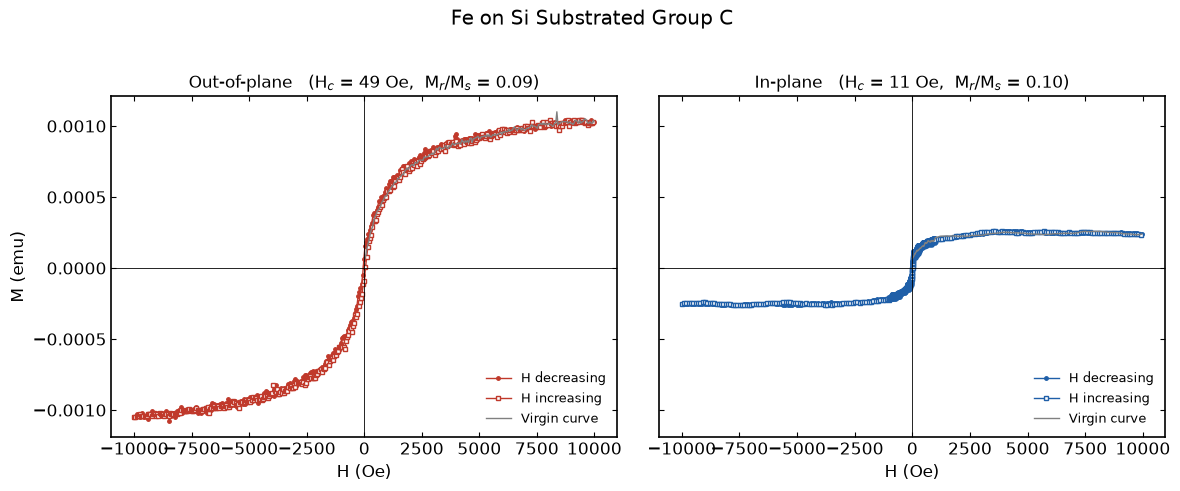

In [28]:
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.2,
                     "xtick.direction": "in", "ytick.direction": "in",
                     "xtick.top": True, "ytick.right": True})

COLORS = {"Out-of-plane": "#C0392B", "In-plane": "#1F5FA8"}

n = len(proc)
fig, axes = plt.subplots(1, n, figsize=(6 * n, 4.8), sharey=True, squeeze=False)
axes = axes[0]
for ax, (label, d) in zip(axes, proc.items()):
    c = COLORS.get(label, None)
    virgin, desc, asc = split_branches(d)
    ax.plot(desc.H, desc.M, "-o", ms=2.5, lw=1, color=c, label="H decreasing")
    ax.plot(asc.H,  asc.M,  "-s", ms=2.5, lw=1, color=c, mfc="white", label="H increasing")
    if SHOW_VIRGIN_CURVE and len(virgin) > 2:
        ax.plot(virgin.H, virgin.M, "-", lw=1, color="0.5", label="Virgin curve")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    p = params.loc[label]
    ax.set_title(f"{label}   (H$_c$ = {p['Hc (Oe)']:.0f} Oe,  M$_r$/M$_s$ = {p['Mr/Ms']:.2f})", fontsize=12)
    ax.set_xlabel("H (Oe)")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
axes[0].set_ylabel(f"M ({M_UNIT})")
fig.suptitle(SAMPLE_NAME, y=1.02)
fig.tight_layout()

if SAVE_FIGURES:
    OUT_DIR.mkdir(exist_ok=True)
    fig.savefig(OUT_DIR / "MH_OOP_IP_side_by_side.png", dpi=300, bbox_inches="tight")
plt.show()

## Plot 2 — both loops overlaid (normalized M/M$_s$), with low-field zoom

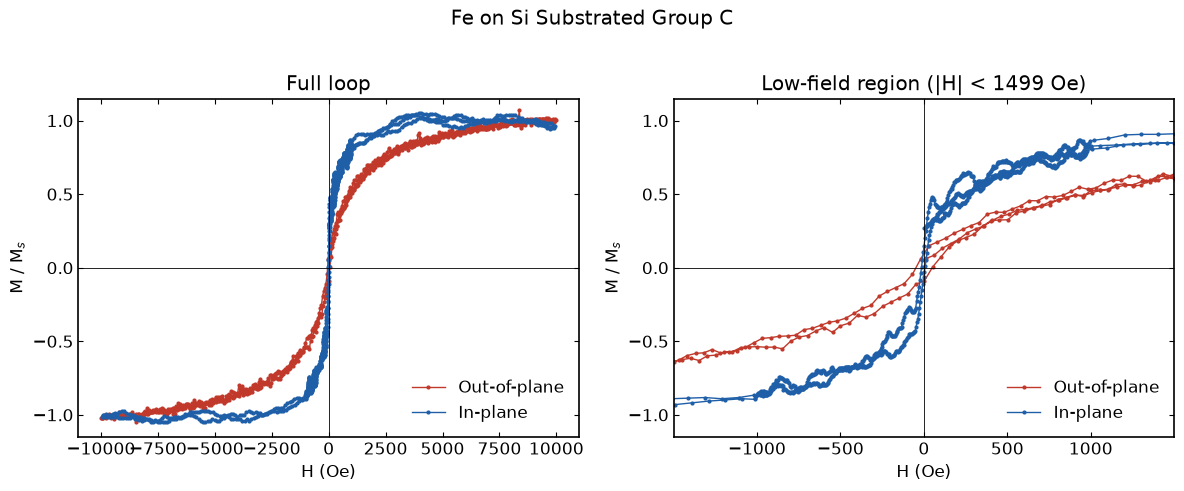

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for label, d in proc.items():
    Ms = params.loc[label, "Ms"]
    for ax in axes:
        ax.plot(d.H, d.M / Ms, "-o", ms=2, lw=1, color=COLORS.get(label), label=label)

axes[0].set_title("Full loop")
zoom = 0.15 * max(d.H.abs().max() for d in proc.values())
axes[1].set_xlim(-zoom, zoom)
axes[1].set_title(f"Low-field region (|H| < {zoom:.0f} Oe)")
for ax in axes:
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("H (Oe)"); ax.set_ylabel("M / M$_s$")
    ax.set_ylim(-1.15, 1.15)
    ax.legend(frameon=False, loc="lower right")
fig.suptitle(SAMPLE_NAME, y=1.02)
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUT_DIR / "MH_OOP_IP_overlay_normalized.png", dpi=300, bbox_inches="tight")
plt.show()

## Export processed data (optional)

In [30]:
if SAVE_FIGURES:
    unit = M_UNIT.replace('$', '').replace('^', '')
    for label, d in proc.items():
        fname = OUT_DIR / f"MH_processed_{label.replace('-', '').replace(' ', '_')}.csv"
        d.rename(columns={"H": "H (Oe)", "M": f"M ({unit})"}).to_csv(fname, index=False)
    params.to_csv(OUT_DIR / "MH_loop_parameters.csv")
    print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\User\Desktop\MT213_2026\Assingment 2\GroupC\GroupC\979D_Fe_VSM\figures
